In [3]:
import lenstronomy

import numpy as np
import os
import matplotlib.pyplot as plt

from lenstronomy.LensModel.lens_model import LensModel
from lenstronomy.LightModel.light_model import LightModel

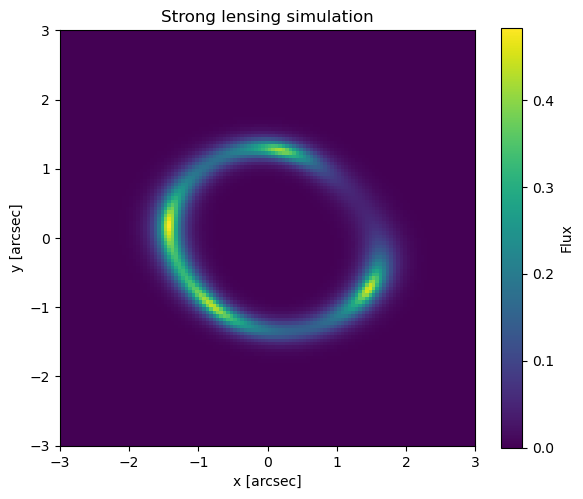

In [4]:
import numpy as np
import matplotlib.pyplot as plt
from lenstronomy.SimulationAPI.sim_api import SimAPI
from lenstronomy.SimulationAPI.ObservationConfig.HST import HST
from lenstronomy.Util.param_util import (phi_q2_ellipticity, shear_polar2cartesian)

# Use HST-like image properties --> this defines how telescope observes the light
kwargs_single_band = {
    "pixel_scale": 0.05,          # arcsec/pixel
    "exposure_time": 524.0,      # seconds
    "magnitude_zero_point": 25.94,
    "read_noise": 5.25,           
    "ccd_gain": 2.0,             
    "sky_brightness": 22.0,   
    "num_exposures": 4,
    "seeing": 0.10,               # PSF FWHM, arcsec
    "psf_type": "GAUSSIAN"}

# number of pixels on each side of image
numpix = 120

# redshift of lens and source
z_lens = 0.222
z_source = 0.609

# Objects in model
kwargs_model = {
    "lens_model_list": ["EPL", "SHEAR"],  # foreground galaxy, 
        # EPL describes the main galaxy's gravitational mass distribution. 
        # SHEAR describes a tidal gravitational field produced by other matter in the lens's environment.
    "source_light_model_list": ["SERSIC_ELLIPSE"]}   # background galaxy
        # SERSIC_ELLIPSE describes the background galaxy's light distribution



# Create simulation
sim = SimAPI(numpix=numpix, kwargs_single_band=kwargs_single_band, kwargs_model=kwargs_model)
    # SimAPI assembles the telescope and model configurations

image_model = sim.image_model_class(kwargs_numerics={"supersampling_factor": 3})
    # image_model_class() constructs the model responsible for generating the lensed image


# Foreground galaxy parameters

# Ballard et al. (2024), Table C1:
# smooth, single-plane, I-band model

theta_E = 1.397     # Einstein radius [arcsec]
gamma = 2.123    # 3D density slope

q = 0.960   # minor / major axis ratio -> q=b/a
phi = np.deg2rad(-70.113) # orientation of the ellipse, measured counterclockwise from the positive x-axis, in radians

# Convert axis ratio and angle to ellipticity components
e1, e2 = phi_q2_ellipticity(phi, q)

# External shear
shear_strength = 0.107
shear_angle = np.deg2rad(-23.243)

gamma1, gamma2 = shear_polar2cartesian(shear_angle, shear_strength)

kwargs_lens = [
    {"theta_E": theta_E,
     "gamma": gamma,
     "e1": e1,
     "e2": e2,
     "center_x": 0.031,
     "center_y": 0.047},
    {"gamma1": gamma1,
     "gamma2": gamma2}]


# Background galaxy parameters
kwargs_source_mag = [{
    "magnitude": 22.76,
    "R_sersic": 0.18,
    "n_sersic": 1,
    "e1": 0.15,
    "e2": 0.05,
    # slightly offset the source from perfect alignment
    "center_x": 0.08,
    "center_y": -0.03}]


_, kwargs_source, _ = sim.magnitude2amplitude(kwargs_source_mag=kwargs_source_mag)\
    # converts the source brightness to the units required by lenstronomy


# Plot lensed image
image_baseline = image_model.image(
    kwargs_lens=kwargs_lens,
    kwargs_source=kwargs_source
)
    # traces light rays backwards from image pixels through the foreground lens to the background source 
    # using the lens equation and generates the PSF image

pixel_scale = kwargs_single_band["pixel_scale"]
image_size = numpix * pixel_scale

plt.figure(figsize=(6, 5))

plt.imshow(
    image_baseline,
    origin="lower",
    extent=[
        -image_size / 2,
        image_size / 2,
        -image_size / 2,
        image_size / 2])

plt.xlabel("x [arcsec]")
plt.ylabel("y [arcsec]")
plt.title("Strong lensing simulation")
plt.colorbar(label="Flux")

plt.tight_layout()
plt.savefig("baseline.png", dpi=300, bbox_inches="tight")
plt.show()


In [7]:
# Get parameters needed from the fits file found from the same HST observation dataset as Ballard et al. (2024)
from astropy.io import fits

filename = "j9op14ohq_flt.fits"

with fits.open(filename) as hdul:
    h = hdul[0].header
    for key in ["EXPTIME", "CCDGAIN",
                "READNSEA", "READNSEB",
                "READNSEC", "READNSED",
                "FILTER1", "FILTER2",
                "DATE-OBS", "PHOTFLAM", "PHOTPLAM"]:
        print(f"{key}: {h.get(key)}")


with fits.open(filename) as hdul:
    for ext in [("SCI", 1), ("SCI", 2)]:
        h = hdul[ext].header
        print(f"\nExtension {ext}")
        for key in ["PHOTFLAM", "PHOTPLAM",
                    "PHOTZPT", "BUNIT", "CCDCHIP"]:
            print(f"{key}: {h.get(key)}")


EXPTIME: 524.0
CCDGAIN: 2
READNSEA: 5.3299999
READNSEB: 4.9899998
READNSEC: 5.5100002
READNSED: 5.1599998
FILTER1: CLEAR1L
FILTER2: F814W
DATE-OBS: 2006-11-03
PHOTFLAM: None
PHOTPLAM: None

Extension ('SCI', 1)
PHOTFLAM: 7.1313412e-20
PHOTPLAM: 8045.1919
PHOTZPT: -21.1
BUNIT: ELECTRONS
CCDCHIP: 2

Extension ('SCI', 2)
PHOTFLAM: 7.1313412e-20
PHOTPLAM: 8045.1919
PHOTZPT: -21.1
BUNIT: ELECTRONS
CCDCHIP: 1


Input Einstein radius: 1.397 arcsec
Median bright-pixel radius: 1.3994356005190092 arcsec
Bright-pixel radial range: 1.1445610512331794 1.729861266113558


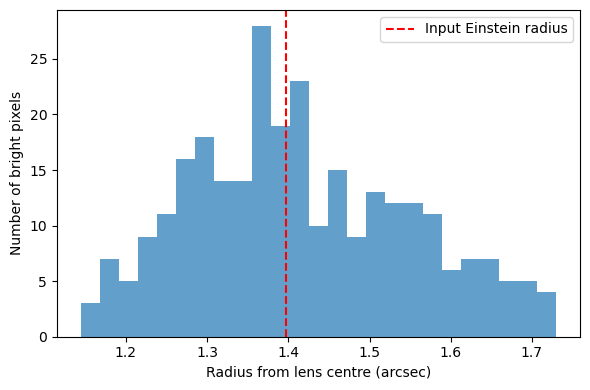

In [9]:

# TEST 1: Einstein-radius scale

x_grid, y_grid = sim.data_class.pixel_coordinates

# Measure distance from the lens mass centre
r = np.sqrt(
    (x_grid - kwargs_lens[0]["center_x"])**2
    + (y_grid - kwargs_lens[0]["center_y"])**2)

# Select pixels brighter than 50% of peak
bright = image_baseline > 0.5 * image_baseline.max()

bright_radii = r[bright] # selects only the distances corresponding to pixels where bright == True

print("Input Einstein radius:", theta_E, "arcsec")
print("Median bright-pixel radius:",
      np.median(bright_radii), "arcsec")
print("Bright-pixel radial range:",
      bright_radii.min(), bright_radii.max())

# Plot distribution of bright-pixel radii
plt.figure(figsize=(6, 4))
plt.hist(bright_radii, bins=25, alpha=0.7)
plt.axvline(theta_E, color="red", linestyle="--", label="Input Einstein radius")

plt.xlabel("Radius from lens centre (arcsec)")
plt.ylabel("Number of bright pixels")
plt.legend()
plt.tight_layout()
plt.savefig("baseline_test1.png", dpi=300, bbox_inches="tight")
plt.show()


In [11]:

# TEST 2: Analytical SIS verification

from lenstronomy.LensModel.lens_model import LensModel

# Circular isothermal lens
sis_model = LensModel(lens_model_list=["EPL"])

sis_params = [{
    "theta_E": theta_E,
    "gamma": 2.0,
    "e1": 0.0,
    "e2": 0.0,
    "center_x": 0.0,
    "center_y": 0.0}]

# Test deflection at 16 different directions
angles = np.linspace(0, 2*np.pi, 16, endpoint=False) # choose 16 equally spaced angles

# get position of these 16 points on a circle that has radius 1.7 times the Einstein radius, 1.7 is just a choice
x = 1.7 * theta_E * np.cos(angles)
y = 1.7 * theta_E * np.sin(angles)

# Deflection angle calculated by lenstronomy at these positions
alpha_x, alpha_y = sis_model.alpha(x, y, sis_params)

# Apply the theoretical equation in notes at these positions
r = np.sqrt(x**2+y**2)
alpha_x_exact = theta_E * x / r
alpha_y_exact = theta_E * y / r

# Calculate maximum error
error = np.max(np.hypot(alpha_x - alpha_x_exact, alpha_y - alpha_y_exact))

print("Maximum deflection error:", error, "arcsec")

if error < 1e-6:
    print("PASS")
else:
    print("FAIL")


# Verify multiple image positions analytically
beta = 0.10  # place background source at x=0.1 arcsec

theta_plus = theta_E + beta
theta_minus = beta - theta_E

beta_x, beta_y = sis_model.ray_shooting(
    np.array([theta_plus, theta_minus]),
    np.array([0.0, 0.0]),
    sis_params)
# .ray_shooting() takes image-plane coordinates and calculates their corresponding source-plane coordinates

print("Expected source position:", beta)
print("Recovered source positions:", beta_x)

if np.allclose(beta_x, beta, atol=1e-6) and np.allclose(beta_y, 0, atol=1e-6):
    print("PASS")
else:
    print("FAIL")


Maximum deflection error: 2.482534153247273e-16 arcsec
PASS
Expected source position: 0.1
Recovered source positions: [0.1 0.1]
PASS


Relative RMS (1 vs 2): 0.007971712051893315
Relative RMS (2 vs 3): 0.001162646795303344
Relative RMS (3 vs 4): 0.00042194383628743344
Relative RMS (4 vs 5): 0.00018915025248503802


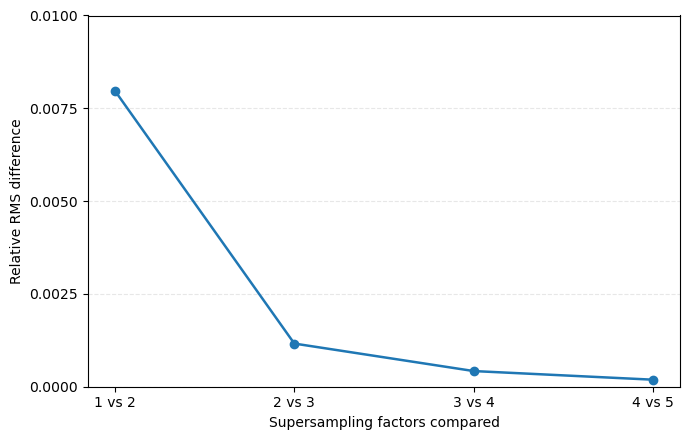

In [13]:
# TEST 4: Numerical convergence

def make_image(supersampling):
    model = sim.image_model_class(kwargs_numerics={"supersampling_factor": supersampling})
    # sim.image_model_class() creates an image-model object using your existing simulation configuration
    # kwargs_numerics is a dictionary containing the numerical settings
    return model.image(kwargs_lens=kwargs_lens, kwargs_source=kwargs_source)

image_1 = make_image(1)
image_2 = make_image(2)
image_3 = make_image(3)
image_4 = make_image(4)
image_5 = make_image(5)

def relative_rms(a, b):
    return np.sqrt(np.mean((a-b)**2)) / np.sqrt(
        np.mean(b**2))

error_12 = relative_rms(image_1, image_2)
error_23 = relative_rms(image_2, image_3)
error_34 = relative_rms(image_3, image_4)
error_45 = relative_rms(image_4, image_5)

print("Relative RMS (1 vs 2):", error_12)
print("Relative RMS (2 vs 3):", error_23)
print("Relative RMS (3 vs 4):", error_34)
print("Relative RMS (4 vs 5):", error_45)

comparisons = ["1 vs 2", "2 vs 3", "3 vs 4", "4 vs 5"]
errors = [error_12, error_23, error_34, error_45]

fig, ax = plt.subplots(figsize=(7, 4.5))

ax.plot(comparisons, errors, marker="o", linewidth=1.8, markersize=6)

ax.set_xlabel("Supersampling factors compared")
ax.set_ylabel("Relative RMS difference")

ax.set_ylim(0, 0.01)
ax.set_yticks(np.arange(0, 0.0101, 0.0025))

ax.grid(axis="y", linestyle="--", alpha=0.3)

plt.tight_layout()
plt.savefig("supersampling_convergence.png", dpi=300, bbox_inches="tight")
plt.show()
